In [55]:
import random
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from collections import deque

In [56]:
#create the map
ship = np.array([
    [0, 0, 0, 0, 0],
    [0, 1, 1, 0, 0],
    [0, 0, 0, 0, 1],
    [0, 1, 0, 0, 0],
    [0, 0, 0, 0, 0]
])

print(ship)

[[0 0 0 0 0]
 [0 1 1 0 0]
 [0 0 0 0 1]
 [0 1 0 0 0]
 [0 0 0 0 0]]


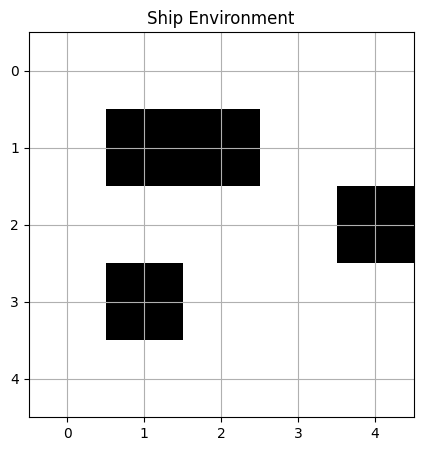

In [57]:
#draw the map
plt.figure(figsize=(5, 5))
plt.imshow(ship, cmap="Greys")

plt.xticks(range(5))
plt.yticks(range(5))
plt.grid()

plt.title("Ship Environment")
plt.show()

In [58]:
def bfs(ship, start, goal):
#define the function and the ship map, start and goal

    queue = deque([start])
    visited = {start}
    parent = {start: None}#record the previous step

    directions = [
        (-1, 0), (1, 0), (0, -1), (0, 1)]

#get the position
    while queue:

        current = queue.popleft()

        if current == goal:
            break

        row, col = current

        for dr, dc in directions:

            nr = row + dr
            nc = col + dc
            neighbor = (nr, nc)

            if (
                0 <= nr < ship.shape[0]
                and 0 <= nc < ship.shape[1]
                and ship[nr, nc] == 0
                and neighbor not in visited
            ):

                visited.add(neighbor)
                parent[neighbor] = current
                queue.append(neighbor)

    if goal not in visited:
        return None

    path = []
    current = goal

    while current is not None:
        path.append(current)
        current = parent[current]

    path.reverse()

    return path

In [59]:
#test the BFS
start = (0, 0)
goal = (4, 4)

path = bfs(ship, start, goal)

print("Shortest path:", path)

if path is not None:
    print("number of moves:", len(path) - 1)

Shortest path: [(0, 0), (1, 0), (2, 0), (3, 0), (4, 0), (4, 1), (4, 2), (4, 3), (4, 4)]
number of moves: 8


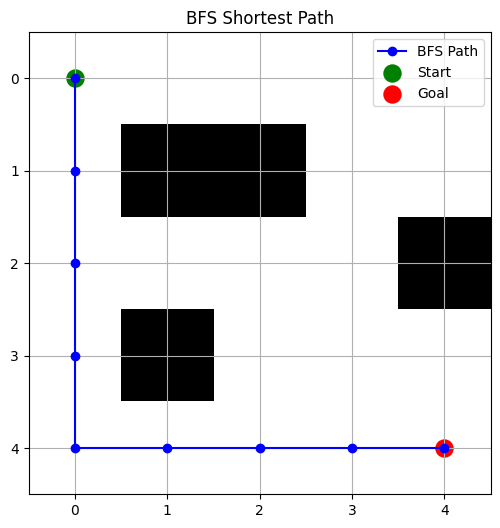

In [60]:
#plt
plt.figure(figsize=(6, 6))
plt.imshow(ship, cmap="Greys")

if path is not None:
    rows = [p[0] for p in path]
    cols = [p[1] for p in path]

    plt.plot(cols, rows, "b-o", label="BFS Path")

plt.scatter(start[1], start[0],
            color="green", s=150, label="Start")

plt.scatter(goal[1], goal[0],
            color="red", s=150, label="Goal")

plt.xticks(range(ship.shape[1]))
plt.yticks(range(ship.shape[0]))
plt.grid()

plt.title("BFS Shortest Path")
plt.legend()
plt.show()

In [61]:
#Type A detector
def detector_type_a(locator_pos, lost_pos, k):

    lr, lc = locator_pos
    br, bc = lost_pos
    #LocatorBot current position
    if locator_pos == lost_pos:
        return "FOUND"

    if abs(lr - br) <= k and abs(lc - bc) <= k:
        return "PING"

    return "NO PING"

locator_pos = (2, 2)
lost_pos = (3, 3)

print(detector_type_a(locator_pos, lost_pos, 1))
print(detector_type_a(locator_pos, lost_pos, 0))
print(detector_type_a(locator_pos, locator_pos, 1))

PING
NO PING
FOUND


In [62]:
possible_positions = set()

for r in range(ship.shape[0]):
    for c in range(ship.shape[1]):

        if ship[r, c] == 0:
            possible_positions.add((r, c))

print("Possible positions:", len(possible_positions))

Possible positions: 21


In [63]:
def update_knowledge_type_a(possible_positions, locator_pos, k, result):

    lr, lc = locator_pos

    detection_area = set()

    for r, c in possible_positions:
        if abs(r - lr) <= k and abs(c - lc) <= k:
            detection_area.add((r, c))

    if result == "PING":
        return possible_positions & detection_area

    elif result == "NO PING":
        return possible_positions - detection_area

    elif result == "FOUND":
        return {locator_pos}

    return possible_positions

In [64]:
#test knowledgebase update
locator_pos = (2, 2)
lost_pos = (3, 3)
k = 1

result = detector_type_a(locator_pos, lost_pos, k)

new_positions = update_knowledge_type_a(
    possible_positions,
    locator_pos,
    k,
    result
)

print("Detector result:", result)
print("Before update:", len(possible_positions))
print("After update:", len(new_positions))
print("Remaining positions:", sorted(new_positions))

Detector result: PING
Before update: 21
After update: 6
Remaining positions: [(1, 3), (2, 1), (2, 2), (2, 3), (3, 2), (3, 3)]


In [65]:
#realize baseline strategy
def find_nearest_position(ship, current_pos, possible_positions):

    nearest_positions = []
    shortest_distance = float("inf")

    for pos in sorted(possible_positions):

        if pos == current_pos:
            continue

        path = bfs(ship, current_pos, pos)

        if path is None:
            continue

        distance = len(path) - 1

        if distance < shortest_distance:
            shortest_distance = distance
            nearest_positions = [pos]

        elif distance == shortest_distance:
            nearest_positions.append(pos)

    if not nearest_positions:
        return None

    return random.choice(nearest_positions)

In [66]:
#test 
current_pos = (2, 2)

nearest = find_nearest_position(
    ship,
    current_pos,
    new_positions
)

print("Nearest possible position:", nearest)
print("Shortest path:", bfs(ship, current_pos, nearest))

Nearest possible position: (3, 2)
Shortest path: [(2, 2), (3, 2)]


In [67]:
#baselineA
def baseline_type_a(ship, start, lost_pos, k):

    current_pos = start
    full_path = [start]

    possible_positions = {
        (r, c)
        for r in range(ship.shape[0])
        for c in range(ship.shape[1])
        if ship[r, c] == 0
    }

    moves = 0
    detections = 0

    while True:

        #run detector
        result = detector_type_a(current_pos, lost_pos, k)
        detections += 1

        if result == "FOUND":
            break

        #update knowledge base
        possible_positions = update_knowledge_type_a(
            possible_positions,
            current_pos,
            k,
            result
        )

        #current cell is confirmed empty
        possible_positions.discard(current_pos)

        #find nearest possible location
        target = find_nearest_position(
            ship,
            current_pos,
            possible_positions
        )

        if target is None:
            raise RuntimeError("No reachable candidate remains.")

        #move to target using BFS
        path = bfs(ship, current_pos, target)

        moves += len(path) - 1
        full_path.extend(path[1:])
        current_pos = target

    total_cost = moves + 0.5 * detections

    return {
        "moves": moves,
        "detections": detections,
        "total_cost": total_cost,
        "path": full_path
    }

In [68]:
#test
random.seed(42)

start = (0, 0)
lost_pos = (4, 4)
k = 1

result = baseline_type_a(ship, start, lost_pos, k)

print(result)

{'moves': 16, 'detections': 8, 'total_cost': 20.0, 'path': [(0, 0), (0, 1), (0, 2), (0, 3), (0, 4), (1, 4), (1, 3), (2, 3), (2, 2), (2, 1), (2, 0), (3, 0), (4, 0), (4, 1), (4, 2), (4, 3), (4, 4)]}


In [69]:
random.seed(42)

result = baseline_type_a(
    ship,
    (0, 0),
    (4, 4),
    1
)

print("Moves:", result["moves"])
print("Detections:", result["detections"])
print("Total Cost:", result["total_cost"])
print("Path:", result["path"])

assert len(result["path"]) - 1 == result["moves"]

Moves: 16
Detections: 8
Total Cost: 20.0
Path: [(0, 0), (0, 1), (0, 2), (0, 3), (0, 4), (1, 4), (1, 3), (2, 3), (2, 2), (2, 1), (2, 0), (3, 0), (4, 0), (4, 1), (4, 2), (4, 3), (4, 4)]


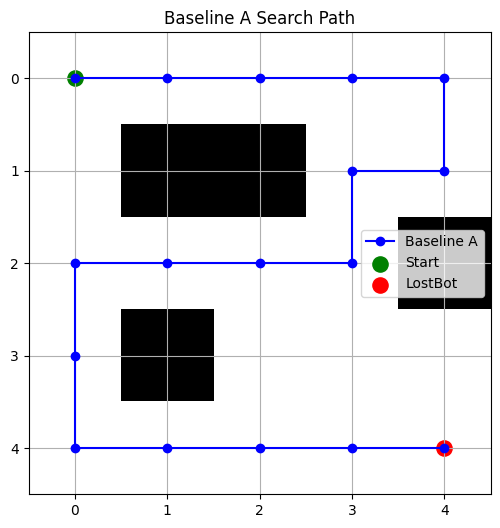

In [70]:
path = result["path"]

rows = [p[0] for p in path]
cols = [p[1] for p in path]

plt.figure(figsize=(6, 6))
plt.imshow(ship, cmap="Greys")

plt.plot(cols, rows, "b-o", label="Baseline A")

plt.scatter(0, 0, color="green", s=120, label="Start")
plt.scatter(4, 4, color="red", s=120, label="LostBot")

plt.xticks(range(ship.shape[1]))
plt.yticks(range(ship.shape[0]))
plt.grid()
plt.legend()
plt.title("Baseline A Search Path")

plt.show()

In [71]:
def information_gain_type_a(possible_positions, pos, k):

    if not possible_positions:
        return 0

    r, c = pos

    inside = 0

    for pr, pc in possible_positions:
        if abs(pr - r) <= k and abs(pc - c) <= k:
            inside += 1

    p = inside / len(possible_positions)

    if p == 0 or p == 1:
        return 0

    ig = -p * math.log2(p) - (1 - p) * math.log2(1 - p)

    return ig

In [72]:
test_positions = {
    (0, 0), (0, 1), (0, 2),
    (1, 0), (1, 1), (1, 2)
}

print(information_gain_type_a(test_positions, (0, 0), 1))
print(information_gain_type_a(test_positions, (0, 1), 1))

0.9182958340544896
0


In [73]:
#select the detect target
def choose_detection_target(ship, current_pos, possible_positions, k, beta=0.95):

    candidates = []

    for r in range(ship.shape[0]):
        for c in range(ship.shape[1]):

            if ship[r, c] == 1:
                continue

            pos = (r, c)
            path = bfs(ship, current_pos, pos)

            if path is None:
                continue

            ig = information_gain_type_a(possible_positions, pos, k)
            distance = len(path) - 1

            candidates.append((pos, ig, distance))

    if not candidates:
        return None

    max_ig = max(item[1] for item in candidates)

    if max_ig == 0:
        return find_nearest_position(
            ship, current_pos, possible_positions
        )

    good_positions = [
        item for item in candidates
        if item[1] >= beta * max_ig
    ]

    best = min(good_positions, key=lambda x: (x[2], -x[1]))

    return best[0]

In [74]:
current_pos = (0, 0)
k = 1

target = choose_detection_target(
    ship,
    current_pos,
    possible_positions,
    k
)

print("Selected detection target:", target)

print("Information Gain:",
      information_gain_type_a(possible_positions, target, k))

print("Shortest Path:", bfs(ship, current_pos, target))

Selected detection target: (1, 3)
Information Gain: 0.9182958340544896
Shortest Path: [(0, 0), (0, 1), (0, 2), (0, 3), (1, 3)]


In [75]:
#realize Improved TypeA
def improved_type_a(ship, start, lost_pos, k, beta=0.95):

    current_pos = start

    possible_positions = {
        (r, c)
        for r in range(ship.shape[0])
        for c in range(ship.shape[1])
        if ship[r, c] == 0
    }

    moves = 0
    detections = 0
    full_path = [start]

    while True:

        #first check the current position
        result = detector_type_a(current_pos, lost_pos, k)
        detections += 1

        if result == "FOUND":
            break

        possible_positions = update_knowledge_type_a(
            possible_positions, current_pos, k, result
        )

        possible_positions.discard(current_pos)

        #choose a useful detection location
        target = choose_detection_target(
            ship, current_pos, possible_positions, k, beta
        )

        if target is None:
            raise RuntimeError("No reachable candidate remains.")

        #if already at target, choose nearest possible location
        if target == current_pos:
            target = find_nearest_position(
                ship, current_pos, possible_positions
            )

        path = bfs(ship, current_pos, target)

        moves += len(path) - 1
        full_path.extend(path[1:])
        current_pos = target

    total_cost = moves + 0.5 * detections

    return {
        "moves": moves,
        "detections": detections,
        "total_cost": total_cost,
        "path": full_path
    }

In [76]:
random.seed(42)
#test improvedA
improved_result = improved_type_a(
    ship,
    (0, 0),
    (4, 4),
    1
)

print(improved_result)

print("Baseline:", result["total_cost"])
print("Improved:", improved_result["total_cost"])

{'moves': 12, 'detections': 6, 'total_cost': 15.0, 'path': [(0, 0), (0, 1), (0, 2), (0, 3), (1, 3), (2, 3), (3, 3), (2, 3), (3, 3), (3, 2), (4, 2), (4, 3), (4, 4)]}
Baseline: 20.0
Improved: 15.0


In [77]:
k_values = [0, 1, 2, 3, 4] # r of different tests
num_trials = 100 #repeat each k 100times
#get the avaliable cells
open_cells = [
    (r, c)
    for r in range(ship.shape[0])
    for c in range(ship.shape[1])
    if ship[r, c] == 0
]
#choose 2 diff position randomly
random.seed(440)

start, lost_pos = random.sample(open_cells, 2)

print("LocatorBot:", start)
print("LostBot:", lost_pos)

LocatorBot: (0, 3)
LostBot: (0, 2)


In [78]:
random.seed(440)

results = []

for k in k_values:

    for trial in range(num_trials):

        #random starting and target positions
        start, lost_pos = random.sample(open_cells, 2)

        #baseline A
        baseline = baseline_type_a(
            ship, start, lost_pos, k
        )

        #improved A
        improved = improved_type_a(
            ship, start, lost_pos, k
        )

        results.append({
            "k": k,
            "trial": trial,
            "baseline_cost": baseline["total_cost"],
            "improved_cost": improved["total_cost"],
            "baseline_moves": baseline["moves"],
            "improved_moves": improved["moves"],
            "baseline_detections": baseline["detections"],
            "improved_detections": improved["detections"]
        })

print("Experiments completed:", len(results))

Experiments completed: 500


In [79]:
df = pd.DataFrame(results)

summary = df.groupby("k")[
    ["baseline_cost", "improved_cost"]
].mean()

summary["improvement_%"] = (
    (summary["baseline_cost"] - summary["improved_cost"])
    / summary["baseline_cost"] * 100
)

display(summary.round(2))

,baseline_cost,improved_cost,improvement_%
k,,,
0,18.03,16.29,9.65
1,8.88,11.20,-26.11
2,8.94,15.20,-70.06
3,11.21,17.12,-52.72
4,17.80,18.55,-4.19


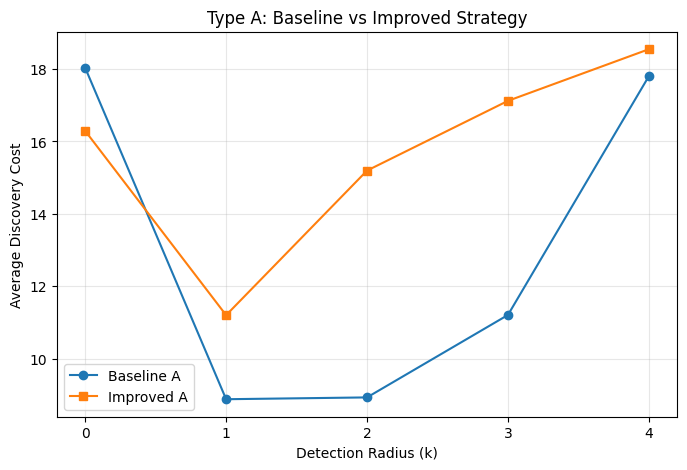

In [80]:
plt.figure(figsize=(8, 5))

plt.plot(
    summary.index,
    summary["baseline_cost"],
    marker="o",
    label="Baseline A"
)

plt.plot(
    summary.index,
    summary["improved_cost"],
    marker="s",
    label="Improved A"
)

plt.xlabel("Detection Radius (k)")
plt.ylabel("Average Discovery Cost")
plt.title("Type A: Baseline vs Improved Strategy")

plt.xticks(k_values)
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [81]:
#improvement
def choose_detection_target_v2(ship, current_pos, possible_positions, k):

    best_target = None
    best_score = -1

    for r in range(ship.shape[0]):
        for c in range(ship.shape[1]):

            if ship[r, c] == 1:
                continue

            pos = (r, c)

            path = bfs(ship, current_pos, pos)

            if path is None:
                continue

            distance = len(path) - 1

            ig = information_gain_type_a(
                possible_positions, pos, k
            )

            score = ig / (distance + 1)

            if score > best_score:
                best_score = score
                best_target = pos

    return best_target

In [82]:
current_pos = (0, 0)
k = 2

target = choose_detection_target_v2(
    ship,
    current_pos,
    possible_positions,
    k
)

print("New target:", target)
print("Distance:", len(bfs(ship, current_pos, target)) - 1)
print("Information Gain:",
      information_gain_type_a(possible_positions, target, k))

New target: (0, 0)
Distance: 0
Information Gain: 0.9182958340544896


In [83]:
def should_detect_type_a(possible_positions, current_pos, k):

    ig = information_gain_type_a(
        possible_positions,
        current_pos,
        k
    )

    return ig > 0

In [84]:
#test adaptive detection
current_pos = (0, 0)
k = 2

print("Before detection:",
      should_detect_type_a(possible_positions, current_pos, k))

result = detector_type_a(current_pos, (4, 4), k)

updated_positions = update_knowledge_type_a(
    possible_positions,
    current_pos,
    k,
    result
)

print("Detector result:", result)

print("After detection:",
      should_detect_type_a(updated_positions, current_pos, k))

Before detection: True
Detector result: NO PING
After detection: False


In [85]:
#V2
def improved_type_a_v2(ship, start, lost_pos, k):

    current_pos = start

    possible_positions = {
        (r, c)
        for r in range(ship.shape[0])
        for c in range(ship.shape[1])
        if ship[r, c] == 0
    }

    moves = 0
    detections = 0
    full_path = [start]

    while True:

        #decide whether to detect
        #also check cells may contain LostBot
        if (current_pos in possible_positions or
            should_detect_type_a(possible_positions, current_pos, k)):

            result = detector_type_a(current_pos, lost_pos, k)
            detections += 1

            if result == "FOUND":
                break

            possible_positions = update_knowledge_type_a(
                possible_positions, current_pos, k, result
            )

            possible_positions.discard(current_pos)

        if not possible_positions:
            raise RuntimeError("No possible positions remain.")

        #choose a new target
        target = choose_detection_target_v2(
            ship, current_pos, possible_positions, k
        )

        #no useful detection is available -> directly search the nearest possible cell
        best_ig = information_gain_type_a(
            possible_positions, target, k
        )

        if best_ig == 0:
            target = find_nearest_position(
                ship, current_pos, possible_positions
            )

        if target is None:
            raise RuntimeError("No reachable target.")

        #move a step along the BFS path
        path = bfs(ship, current_pos, target)

        if path is None or len(path) < 2:
            raise RuntimeError("Cannot make progress.")

        current_pos = path[1]
        moves += 1
        full_path.append(current_pos)

        #the next loop checks for useful detection and replans

    total_cost = moves + 0.5 * detections

    return {
        "moves": moves,
        "detections": detections,
        "total_cost": total_cost,
        "path": full_path
    }

In [86]:
#test V2

random.seed(42)

start = (0, 0)
lost_pos = (4, 4)
k = 1

baseline_result = baseline_type_a(
    ship, start, lost_pos, k
)

random.seed(42)

v1_result = improved_type_a(
    ship, start, lost_pos, k
)

random.seed(42)

v2_result = improved_type_a_v2(
    ship, start, lost_pos, k
)

print("Baseline Cost:", baseline_result["total_cost"])
print("V1 Cost:", v1_result["total_cost"])
print("V2 Cost:", v2_result["total_cost"])

assert v2_result["path"][-1] == lost_pos
assert len(v2_result["path"]) - 1 == v2_result["moves"]


Baseline Cost: 20.0
V1 Cost: 15.0
V2 Cost: 14.5


In [87]:
#repeat
random.seed(440)

results_v2 = []

for k in k_values:
    for trial in range(100):

        start, lost_pos = random.sample(open_cells, 2)

        baseline = baseline_type_a(ship, start, lost_pos, k)
        v1 = improved_type_a(ship, start, lost_pos, k)
        v2 = improved_type_a_v2(ship, start, lost_pos, k)

        results_v2.append({
            "k": k,
            "trial": trial,
            "baseline": baseline["total_cost"],
            "v1": v1["total_cost"],
            "v2": v2["total_cost"]
        })

print("Experiments completed:", len(results_v2))

Experiments completed: 500


In [88]:
df_v2 = pd.DataFrame(results_v2)

summary_v2 = df_v2.groupby("k")[
    ["baseline", "v1", "v2"]
].mean()

display(summary_v2.round(2))

,baseline,v1,v2
k,,,
0,17.96,16.80,16.80
1,9.65,10.23,10.04
2,9.24,14.79,11.70
3,11.92,17.42,12.40
4,17.84,16.92,17.30


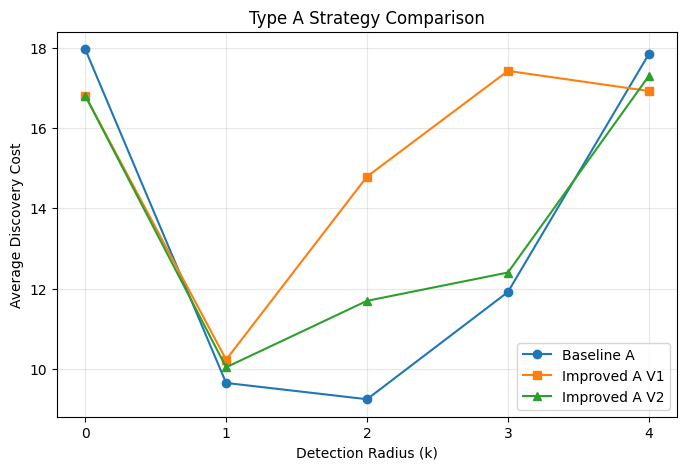

In [89]:
plt.figure(figsize=(8, 5))

plt.plot(summary_v2.index, summary_v2["baseline"],
         marker="o", label="Baseline A")

plt.plot(summary_v2.index, summary_v2["v1"],
         marker="s", label="Improved A V1")

plt.plot(summary_v2.index, summary_v2["v2"],
         marker="^", label="Improved A V2")

plt.xlabel("Detection Radius (k)")
plt.ylabel("Average Discovery Cost")
plt.title("Type A Strategy Comparison")

plt.xticks(k_values)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [90]:
#estimate remaining cost
def estimate_remaining_cost(n):
    if n == 0:
        return 0

    return 1.5 * (n + 1) / 2

In [91]:
#cal expected cost
def expected_cost_type_a(ship, current_pos, target, possible_positions, k):

    path = bfs(ship, current_pos, target)

    if path is None:
        return float("inf")

    move_cost = len(path) - 1

    r, c = target

    ping_positions = {
        pos for pos in possible_positions
        if abs(pos[0] - r) <= k
        and abs(pos[1] - c) <= k
    }

    no_ping_positions = possible_positions - ping_positions

    n = len(possible_positions)

    if n == 0:
        return 0

    p_ping = len(ping_positions) / n

    cost_ping = estimate_remaining_cost(len(ping_positions))
    cost_no_ping = estimate_remaining_cost(len(no_ping_positions))

    expected_cost = (
        move_cost
        + 0.5
        + p_ping * cost_ping
        + (1 - p_ping) * cost_no_ping
    )

    return expected_cost

def expected_cost_type_a_fast(
    target, possible_positions, k, distances
):
    if target not in distances:
        return float("inf")

    move_cost = distances[target]

    r, c = target

    ping_positions = {
        pos for pos in possible_positions
        if abs(pos[0] - r) <= k
        and abs(pos[1] - c) <= k
    }

    n = len(possible_positions)

    if n == 0:
        return 0

    p_ping = len(ping_positions) / n

    cost_ping = estimate_remaining_cost(
        len(ping_positions)
    )

    cost_no_ping = estimate_remaining_cost(
        n - len(ping_positions)
    )

    return (
        move_cost
        + 0.5
        + p_ping * cost_ping
        + (1 - p_ping) * cost_no_ping
    )

In [92]:
current_pos = (0, 0)
k = 1

print(
    "Target (0,0):",
    expected_cost_type_a(
        ship, current_pos, (0,0), possible_positions, k
    )
)

print(
    "Target (1,3):",
    expected_cost_type_a(
        ship, current_pos, (1,3), possible_positions, k
    )
)

Target (0,0): 13.142857142857144
Target (1,3): 14.0


In [93]:
def choose_target_v3(ship, current_pos, possible_positions, k):

    best_target = None
    lowest_cost = float("inf")

    for r in range(ship.shape[0]):
        for c in range(ship.shape[1]):

            if ship[r, c] == 1:
                continue

            target = (r, c)

            # Avoid detector actions that provide no new information
            ig = information_gain_type_a(
                possible_positions, target, k
            )

            if ig == 0:
                continue

            cost = expected_cost_type_a(
                ship, current_pos, target,
                possible_positions, k
            )

            if cost < lowest_cost:
                lowest_cost = cost
                best_target = target

    # No informative detection is available:
    # search the nearest possible LostBot location
    if best_target is None:
        return find_nearest_position(
            ship, current_pos, possible_positions
        )

    return best_target

In [94]:
current_pos = (0, 0)
k = 1

target = choose_target_v3(
    ship,
    current_pos,
    possible_positions,
    k
)

print("V3 Target:", target)

print("Expected Cost:",
      expected_cost_type_a(
          ship, current_pos, target,
          possible_positions, k
      ))

V3 Target: (1, 0)
Expected Cost: 12.285714285714285


In [95]:
def improved_type_a_v3(ship, start, lost_pos, k):

    current_pos = start

    possible_positions = {
        (r, c)
        for r in range(ship.shape[0])
        for c in range(ship.shape[1])
        if ship[r, c] == 0
    }

    moves = 0
    detections = 0
    full_path = [start]

    while True:

        #check whether detection is useful
        if (current_pos in possible_positions or
            should_detect_type_a(possible_positions, current_pos, k)):

            result = detector_type_a(current_pos, lost_pos, k)
            detections += 1

            if result == "FOUND":
                break

            #update knowledge base
            possible_positions = update_knowledge_type_a(
                possible_positions, current_pos, k, result
            )

            possible_positions.discard(current_pos)

        if not possible_positions:
            raise RuntimeError("No possible positions remain.")

        #select target using expected cost
        target = choose_target_v3(
            ship, current_pos, possible_positions, k
        )

        if target is None:
            raise RuntimeError("No reachable target.")

        #move one step
        path = bfs(ship, current_pos, target)

        if path is None or len(path) < 2:
            raise RuntimeError("Search cannot make progress.")

        current_pos = path[1]
        moves += 1
        full_path.append(current_pos)

    total_cost = moves + 0.5 * detections

    return {
        "moves": moves,
        "detections": detections,
        "total_cost": total_cost,
        "path": full_path
    }

In [96]:
#test 
random.seed(42)

v3_result = improved_type_a_v3(
    ship,
    (0, 0),
    (4, 4),
    1
)

print("V3:", v3_result)

assert v3_result["path"][-1] == (4, 4)
assert len(v3_result["path"]) - 1 == v3_result["moves"]

V3: {'moves': 10, 'detections': 9, 'total_cost': 14.5, 'path': [(0, 0), (0, 1), (0, 2), (0, 3), (1, 3), (2, 3), (3, 3), (3, 2), (4, 2), (4, 3), (4, 4)]}


In [97]:
comparison = pd.DataFrame({
    "Strategy": ["Baseline", "V1", "V2", "V3"],
    "Cost": [
        baseline_result["total_cost"],
        v1_result["total_cost"],
        v2_result["total_cost"],
        v3_result["total_cost"]
    ]
})

display(comparison)

,Strategy,Cost
0,Baseline,20.0
1,V1,15.0
2,V2,14.5
3,V3,14.5


In [98]:
random.seed(440)

test_cases = [
    tuple(random.sample(open_cells, 2))
    for _ in range(100)
]

results_v3 = []

for k in [0, 1, 2, 3, 4]:

    for trial, (start, lost_pos) in enumerate(test_cases):

        random.seed(440 + trial)
        baseline = baseline_type_a(ship, start, lost_pos, k)

        random.seed(440 + trial)
        v1 = improved_type_a(ship, start, lost_pos, k)

        random.seed(440 + trial)
        v2 = improved_type_a_v2(ship, start, lost_pos, k)

        random.seed(440 + trial)
        v3 = improved_type_a_v3(ship, start, lost_pos, k)

        results_v3.append({
            "k": k,
            "trial": trial,
            "baseline": baseline["total_cost"],
            "v1": v1["total_cost"],
            "v2": v2["total_cost"],
            "v3": v3["total_cost"]
        })

df_v3 = pd.DataFrame(results_v3)

summary_v3 = df_v3.groupby("k")[
    ["baseline", "v1", "v2", "v3"]
].mean()

display(summary_v3.round(2))


,baseline,v1,v2,v3
k,,,,
0,16.16,16.33,16.33,16.33
1,9.72,11.31,9.56,9.72
2,9.08,14.48,11.58,11.96
3,10.67,16.60,13.10,13.03
4,16.16,16.16,15.38,15.38


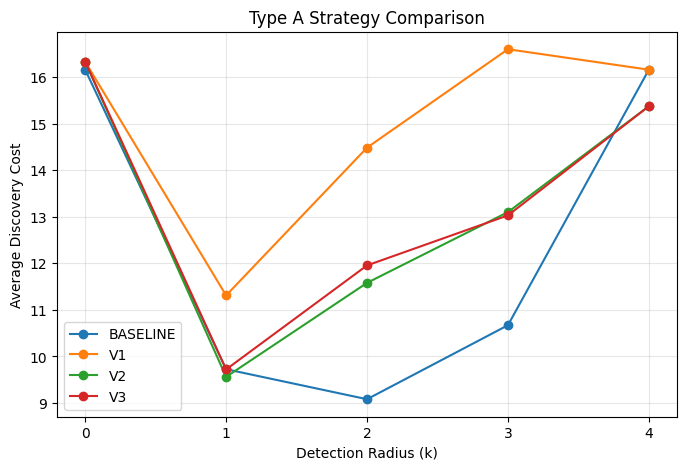

In [99]:
plt.figure(figsize=(8, 5))

for strategy in ["baseline", "v1", "v2", "v3"]:
    plt.plot(
        summary_v3.index,
        summary_v3[strategy],
        marker="o",
        label=strategy.upper()
    )

plt.xlabel("Detection Radius (k)")
plt.ylabel("Average Discovery Cost")
plt.title("Type A Strategy Comparison")
plt.xticks([0, 1, 2, 3, 4])
plt.grid(alpha=0.3)
plt.legend()
plt.show()

In [100]:
import sys
from pathlib import Path

project1_code = Path.cwd().parent / "CS440-Project01-ZhitongGuo" / "Code"

sys.path.insert(0, str(project1_code))

import theShip

print(dir(theShip))

['BLOCKED', 'OPEN', '__builtins__', '__cached__', '__doc__', '__file__', '__loader__', '__name__', '__package__', '__spec__', 'count_open_neighbors', 'find_dead_ends', 'find_ready_to_open', 'generate_ship', 'get_block_neighbors', 'getneighbors', 'random']


In [101]:
import inspect

print([name for name in dir(theShip) if not name.startswith("_")])

print(inspect.signature(theShip.generate_ship))

print("OPEN =", theShip.OPEN)
print("BLOCKED =", theShip.BLOCKED)

['BLOCKED', 'OPEN', 'count_open_neighbors', 'find_dead_ends', 'find_ready_to_open', 'generate_ship', 'get_block_neighbors', 'getneighbors', 'random']
(D, seed=None)
OPEN = 1
BLOCKED = 0


Shape: (30, 30)
Open cells: 585


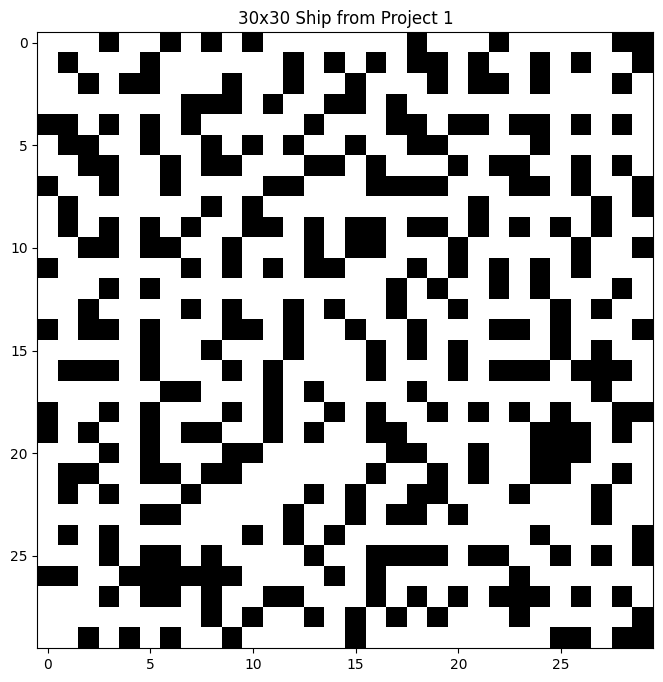

In [102]:
#generate ship using Project 1
ship_p1 = theShip.generate_ship(30, seed=440)

large_ship = 1 - np.array(ship_p1)

print("Shape:", large_ship.shape)
print("Open cells:", np.sum(large_ship == 0))

plt.figure(figsize=(8, 8))
plt.imshow(large_ship, cmap="Greys")
plt.title("30x30 Ship from Project 1")
plt.show()

In [103]:
large_open_cells = [
    (r, c)
    for r in range(large_ship.shape[0])
    for c in range(large_ship.shape[1])
    if large_ship[r, c] == 0
]

start = large_open_cells[0]

connected = all(
    bfs(large_ship, start, pos) is not None
    for pos in large_open_cells
)

print("All open cells connected:", connected)

All open cells connected: True


In [104]:
print("Ship size:", large_ship.shape)
print("Total cells:", large_ship.size)
print("Open cells:", len(large_open_cells))
print("Blocked cells:", np.sum(large_ship == 1))

Ship size: (30, 30)
Total cells: 900
Open cells: 585
Blocked cells: 315


In [105]:
#choose the position
random.seed(440)

large_start, large_lost = random.sample(
    large_open_cells, 2
)

k = 3

print("LocatorBot:", large_start)
print("LostBot:", large_lost)

LocatorBot: (6, 15)
LostBot: (4, 4)


In [106]:
import time

large_results = []

strategies = [
    ("Baseline", baseline_type_a),
    ("V2", improved_type_a_v2),
    ("V3", improved_type_a_v3)
]

for name, strategy in strategies:

    random.seed(42)
    start_time = time.perf_counter()

    result = strategy(
        large_ship,
        large_start,
        large_lost,
        k
    )

    elapsed = time.perf_counter() - start_time

    assert result["path"][-1] == large_lost
    assert len(result["path"]) - 1 == result["moves"]

    large_results.append({
        "Strategy": name,
        "Moves": result["moves"],
        "Detections": result["detections"],
        "Total Cost": result["total_cost"],
        "Runtime (s)": elapsed
    })

display(pd.DataFrame(large_results).round(2))

,Strategy,Moves,Detections,Total Cost,Runtime (s)
0,Baseline,187,38,206.0,4.58
1,V2,129,111,184.5,29.91
2,V3,97,86,140.0,20.85


In [107]:
def bfs_distances(ship, start):

    queue = deque([start])
    distances = {start: 0}

    directions = [
        (-1, 0), (1, 0),
        (0, -1), (0, 1)
    ]

    while queue:

        r, c = queue.popleft()

        for dr, dc in directions:

            nr, nc = r + dr, c + dc
            neighbor = (nr, nc)

            if (
                0 <= nr < ship.shape[0]
                and 0 <= nc < ship.shape[1]
                and ship[nr, nc] == 0
                and neighbor not in distances
            ):

                distances[neighbor] = distances[(r, c)] + 1
                queue.append(neighbor)

    return distances

distances = bfs_distances(large_ship, large_start)

print("reachable cell:", len(distances))
print("distance to LostBot:", distances[large_lost])

assert len(distances) == len(large_open_cells)
assert distances[large_lost] == len(
    bfs(large_ship, large_start, large_lost)
) - 1


reachable cell: 585
distance to LostBot: 25


In [108]:
distances = bfs_distances(large_ship, large_start)

target = large_open_cells[20]

old_cost = expected_cost_type_a(
    large_ship,
    large_start,
    target,
    set(large_open_cells),
    3
)

new_cost = expected_cost_type_a_fast(
    target,
    set(large_open_cells),
    3,
    distances
)

print("Original:", old_cost)
print("Optimized:", new_cost)

assert abs(old_cost - new_cost) < 1e-9

Original: 430.63076923076926
Optimized: 430.63076923076926


In [109]:
#difference from previous choose_target_v3():
#The original choose_target_v3() calls BFS once for each candidate position
#this one run BFS only once and then read the distance from the dictionary
def choose_target_v3_fast(ship, current_pos, possible_positions, k):

    # Run BFS only once
    distances = bfs_distances(ship, current_pos)

    best_target = None
    lowest_cost = float("inf")

    for target in distances:

        # Calculate information gain
        ig = information_gain_type_a(
            possible_positions, target, k
        )

        if ig == 0:
            continue

        # Use precomputed BFS distances
        cost = expected_cost_type_a_fast(
            target,
            possible_positions,
            k,
            distances
        )

        if cost < lowest_cost:
            lowest_cost = cost
            best_target = target

    if best_target is None:
        return find_nearest_position(
            ship, current_pos, possible_positions
        )

    return best_target

In [110]:
#test
#if the assert pass, then the two version choose the same target
current_pos = large_start
possible = set(large_open_cells)
k = 3

old_target = choose_target_v3(
    large_ship, current_pos, possible, k
)

fast_target = choose_target_v3_fast(
    large_ship, current_pos, possible, k
)

print("Original target:", old_target)
print("Fast target:", fast_target)

assert old_target == fast_target

Original target: (7, 14)
Fast target: (7, 14)


In [111]:
#fast V3 -- revise from the previous one
def improved_type_a_v3_fast(ship, start, lost_pos, k):

    current_pos = start

    possible_positions = {
        (r, c)
        for r in range(ship.shape[0])
        for c in range(ship.shape[1])
        if ship[r, c] == 0
    }

    moves = 0
    detections = 0
    full_path = [start]

    while True:

        # adaptive detection
        if (current_pos in possible_positions or
            should_detect_type_a(possible_positions, current_pos, k)):

            result = detector_type_a(current_pos, lost_pos, k)
            detections += 1

            if result == "FOUND":
                break

            possible_positions = update_knowledge_type_a(
                possible_positions, current_pos, k, result
            )

            possible_positions.discard(current_pos)

        if not possible_positions:
            raise RuntimeError("No possible positions remain.")

        #compute all shortest distances with one BFS
        distances = bfs_distances(ship, current_pos)

        best_target = None
        lowest_cost = float("inf")

        #chose target using the expect cost
        for target in distances:

            ig = information_gain_type_a(
                possible_positions, target, k
            )

            if ig == 0:
                continue

            cost = expected_cost_type_a_fast(
                target,
                possible_positions,
                k,
                distances
            )

            if cost < lowest_cost:
                lowest_cost = cost
                best_target = target

        if best_target is None:

            best_target = min(
                possible_positions,
                key=lambda pos: distances.get(
                    pos, float("inf")
                )
            )

        target = best_target

        #one step toward target
        path = bfs(ship, current_pos, target)

        if path is None:
            raise RuntimeError("Target is unreachable.")

        if len(path) < 2:
            raise RuntimeError("Search cannot make progress.")

        current_pos = path[1]
        moves += 1
        full_path.append(current_pos)

    total_cost = moves + 0.5 * detections

    return {
        "moves": moves,
        "detections": detections,
        "total_cost": total_cost,
        "path": full_path
    }

In [112]:
import time

start_time = time.perf_counter()

fast_result = improved_type_a_v3_fast(
    large_ship,
    large_start,
    large_lost,
    3
)

elapsed = time.perf_counter() - start_time

print("Moves:", fast_result["moves"])
print("Detections:", fast_result["detections"])
print("Total Cost:", fast_result["total_cost"])
print("Runtime:", round(elapsed, 3), "seconds")

assert fast_result["path"][-1] == large_lost
assert len(fast_result["path"]) - 1 == fast_result["moves"]

Moves: 97
Detections: 86
Total Cost: 140.0
Runtime: 2.724 seconds


In [113]:
#start the large map experiment
#set parameters
k_values_large = [0, 1, 2, 3, 5, 7, 10, 15]
num_trials = 20

random.seed(440)

test_cases = [
    tuple(random.sample(large_open_cells, 2))
    for _ in range(num_trials)
]

In [114]:
results_large = []

for k in k_values_large:

    for trial, (start, lost_pos) in enumerate(test_cases):

        random.seed(440 + trial)
        baseline = baseline_type_a(
            large_ship, start, lost_pos, k
        )

        random.seed(440 + trial)
        improved = improved_type_a_v3_fast(
            large_ship, start, lost_pos, k
        )

        results_large.append({
            "k": k,
            "trial": trial,
            "baseline_cost": baseline["total_cost"],
            "improved_cost": improved["total_cost"],
            "baseline_moves": baseline["moves"],
            "improved_moves": improved["moves"],
            "baseline_detections": baseline["detections"],
            "improved_detections": improved["detections"]
        })

    print("Finished k =", k)

Finished k = 0
Finished k = 1
Finished k = 2
Finished k = 3
Finished k = 5
Finished k = 7
Finished k = 10
Finished k = 15


In [115]:
df_large = pd.DataFrame(results_large)

summary_large = df_large.groupby("k")[
    ["baseline_cost", "improved_cost"]
].mean()

summary_large["improvement_%"] = (
    (summary_large["baseline_cost"]
     - summary_large["improved_cost"])
    / summary_large["baseline_cost"] * 100
)

display(summary_large.round(2))

,baseline_cost,improved_cost,improvement_%
k,,,
0,503.52,535.45,-6.34
1,324.68,349.05,-7.51
2,148.35,168.22,-13.40
3,142.88,137.35,3.87
5,86.30,87.20,-1.04
7,77.75,80.03,-2.93
10,106.48,72.18,32.21
15,124.40,108.15,13.06


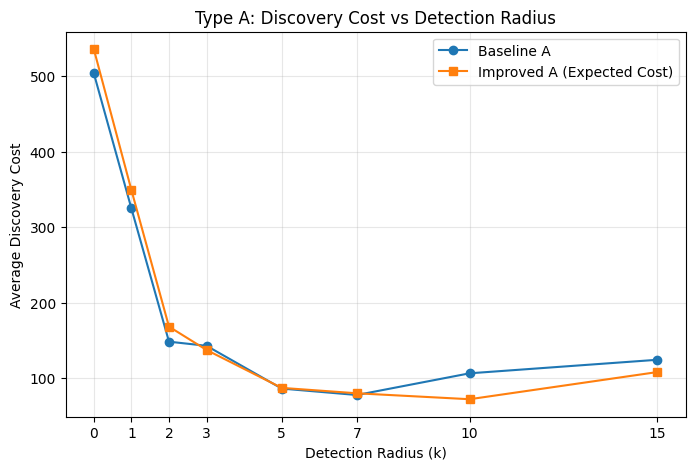

In [116]:
plt.figure(figsize=(8, 5))

plt.plot(
    summary_large.index,
    summary_large["baseline_cost"],
    marker="o",
    label="Baseline A"
)

plt.plot(
    summary_large.index,
    summary_large["improved_cost"],
    marker="s",
    label="Improved A (Expected Cost)"
)

plt.xlabel("Detection Radius (k)")
plt.ylabel("Average Discovery Cost")
plt.title("Type A: Discovery Cost vs Detection Radius")
plt.xticks(k_values_large)
plt.grid(alpha=0.3)
plt.legend()
plt.show()

### Type B: Probabilistic Detector + Bayesian Inference

In [117]:
#detector B
def detector_type_b(locator_pos, lost_pos, alpha):

    if locator_pos == lost_pos:
        return "FOUND"

    r1, c1 = locator_pos
    r2, c2 = lost_pos

    # Euclidean distance
    distance = math.sqrt(
        (r1 - r2)**2 + (c1 - c2)**2
    )

    # Probability of receiving a ping
    p_ping = math.exp(-alpha * (distance - 1))

    if random.random() < p_ping:
        return "PING"

    return "NO PING"

In [118]:
random.seed(440)

locator_pos = (0, 0)
lost_pos = (3, 4)
alpha = 0.2

for i in range(10):
    print(detector_type_b(locator_pos, lost_pos, alpha))

PING
PING
PING
PING
PING
PING
NO PING
NO PING
NO PING
NO PING


In [119]:
def initialize_knowledge_b(ship):

    open_cells = [
        (r, c)
        for r in range(ship.shape[0])
        for c in range(ship.shape[1])
        if ship[r, c] == 0
    ]

    probability = 1 / len(open_cells)

    return {
        pos: probability
        for pos in open_cells
    }

In [121]:
#using bayes rule

def update_knowledge_type_b(knowledge, locator_pos, alpha, result):

    updated = {}

    for pos, prior in knowledge.items():

        if pos == locator_pos:
            updated[pos] = 0
            continue

        distance = math.dist(locator_pos, pos)

        p_ping = math.exp(-alpha * (distance - 1))

        if result == "PING":
            likelihood = p_ping
        else:
            likelihood = 1 - p_ping

        updated[pos] = prior * likelihood

    total = sum(updated.values())

    if total <= 0:
        raise RuntimeError("Observation has zero probability.")

    return {
        pos: value / total
        for pos, value in updated.items()
    }

knowledge_b = initialize_knowledge_b(ship)

#test

print("Before:", sum(knowledge_b.values()))

updated_b = update_knowledge_type_b(
    knowledge_b,
    (0, 0),
    0.2,
    "PING"
)

print("After:", sum(updated_b.values()))

top_positions = sorted(
    updated_b.items(),
    key=lambda item: item[1],
    reverse=True
)[:5]

display(pd.DataFrame(
    top_positions,
    columns=["Position", "Posterior Probability"]
))

Before: 1.0000000000000004
After: 0.9999999999999999


,Position,Posterior Probability
0,"(0, 1)",0.078291
1,"(1, 0)",0.078291
2,"(0, 2)",0.064099
3,"(2, 0)",0.064099
4,"(2, 1)",0.061143


In [122]:
#Implement Baseline Strategy B
#get the avaliabel position

def find_most_likely_position(ship, current_pos, knowledge):

    max_probability = max(knowledge.values())

    candidates = [
        pos for pos, prob in knowledge.items()
        if abs(prob - max_probability) < 1e-12
        and pos != current_pos
    ]

    # Compute BFS distances once
    distances = bfs_distances(ship, current_pos)

    min_distance = min(
        distances[pos] for pos in candidates
    )

    nearest_candidates = [
        pos for pos in candidates
        if distances[pos] == min_distance
    ]

    return random.choice(nearest_candidates)

In [123]:
random.seed(440)

target = find_most_likely_position(
    ship,
    (0, 0),
    updated_b
)

print("Most likely target:", target)
print("Posterior probability:", updated_b[target])
print("BFS distance:", len(bfs(ship, (0, 0), target)) - 1)

Most likely target: (0, 1)
Posterior probability: 0.07829118579169975
BFS distance: 1


In [124]:

def baseline_type_b(ship, start, lost_pos, alpha):

    current_pos = start
    knowledge = initialize_knowledge_b(ship)

    moves = 0
    detections = 0
    full_path = [start]

    while True:

        result = detector_type_b(
            current_pos, lost_pos, alpha
        )
        detections += 1

        if result == "FOUND":
            break

        knowledge = update_knowledge_type_b(
            knowledge, current_pos, alpha, result
        )

        target = find_most_likely_position(
            ship, current_pos, knowledge
        )

        path = bfs(ship, current_pos, target)

        if path is None:
            raise RuntimeError("Target is unreachable.")

        moves += len(path) - 1
        full_path.extend(path[1:])
        current_pos = target

    total_cost = moves + 0.5 * detections

    return {
        "moves": moves,
        "detections": detections,
        "total_cost": total_cost,
        "path": full_path
    }

#test on the small map
random.seed(440)

baseline_b_result = baseline_type_b(
    ship,
    (0, 0),
    (4, 4),
    alpha=0.2
)

print("Moves:", baseline_b_result["moves"])
print("Detections:", baseline_b_result["detections"])
print("Total Cost:", baseline_b_result["total_cost"])

assert baseline_b_result["path"][-1] == (4, 4)
assert len(baseline_b_result["path"]) - 1 == baseline_b_result["moves"]

Moves: 18
Detections: 9
Total Cost: 22.5


In [125]:
#improve type B

def choose_target_type_b(ship, current_pos, knowledge):

    distances = bfs_distances(ship, current_pos)

    best_target = None
    best_score = -1

    for pos, probability in knowledge.items():

        if pos == current_pos:
            continue

        if pos not in distances:
            continue

        if probability <= 0:
            continue

        distance = distances[pos]

        score = probability / (distance + 0.5)

        if score > best_score:
            best_score = score
            best_target = pos

    return best_target

target = choose_target_type_b(
    ship,
    (0, 0),
    updated_b
)

print("Improved B target:", target)
print("Probability:", updated_b[target])
print("Distance:", len(bfs(ship, (0, 0), target)) - 1)

Improved B target: (0, 1)
Probability: 0.07829118579169975
Distance: 1


In [127]:
def improved_type_b(ship, start, lost_pos, alpha):

    current_pos = start
    knowledge = initialize_knowledge_b(ship)

    moves = 0
    detections = 0
    full_path = [start]

    while True:

        result = detector_type_b(
            current_pos, lost_pos, alpha
        )
        detections += 1

        if result == "FOUND":
            break

        knowledge = update_knowledge_type_b(
            knowledge, current_pos, alpha, result
        )

        target = choose_target_type_b(
            ship, current_pos, knowledge
        )

        if target is None:
            raise RuntimeError("No reachable target remains.")

        path = bfs(ship, current_pos, target)

        if path is None:
            raise RuntimeError("Target is unreachable.")

        moves += len(path) - 1
        full_path.extend(path[1:])
        current_pos = target

    total_cost = moves + 0.5 * detections

    return {
        "moves": moves,
        "detections": detections,
        "total_cost": total_cost,
        "path": full_path
    }
random.seed(440)

improved_b_result = improved_type_b(
    ship,
    (0, 0),
    (4, 4),
    alpha=0.2
)

print("Moves:", improved_b_result["moves"])
print("Detections:", improved_b_result["detections"])
print("Total Cost:", improved_b_result["total_cost"])

assert improved_b_result["path"][-1] == (4, 4)
assert len(improved_b_result["path"]) - 1 == improved_b_result["moves"]

Moves: 26
Detections: 17
Total Cost: 34.5


In [128]:
random.seed(440)
baseline_b = baseline_type_b(ship, (0, 0), (4, 4), 0.2)

random.seed(440)
improved_b = improved_type_b(ship, (0, 0), (4, 4), 0.2)

comparison_b = pd.DataFrame([
    {"Strategy": "Baseline B", **{
        key: baseline_b[key]
        for key in ["moves", "detections", "total_cost"]
    }},
    {"Strategy": "Improved B", **{
        key: improved_b[key]
        for key in ["moves", "detections", "total_cost"]
    }}
])

display(comparison_b)

,Strategy,moves,detections,total_cost
0,Baseline B,18,9,22.5
1,Improved B,26,17,34.5


In [129]:
alpha_values = [0.01, 0.03, 0.05, 0.1, 0.2, 0.4, 0.8]
num_trials_b = 20

In [130]:
#small exp 5*5
random.seed(440)

test_cases_b = [
    tuple(random.sample(open_cells, 2))
    for _ in range(num_trials_b)
]

results_b = []

for alpha in alpha_values:

    for trial, (start, lost_pos) in enumerate(test_cases_b):

        random.seed(440 + trial)
        baseline = baseline_type_b(
            ship, start, lost_pos, alpha
        )

        random.seed(440 + trial)
        improved = improved_type_b(
            ship, start, lost_pos, alpha
        )

        results_b.append({
            "alpha": alpha,
            "trial": trial,
            "baseline_cost": baseline["total_cost"],
            "improved_cost": improved["total_cost"]
        })

    print("Finished alpha =", alpha)


Finished alpha = 0.01
Finished alpha = 0.03
Finished alpha = 0.05
Finished alpha = 0.1
Finished alpha = 0.2
Finished alpha = 0.4
Finished alpha = 0.8


In [131]:
df_b = pd.DataFrame(results_b)

summary_b = df_b.groupby("alpha")[
    ["baseline_cost", "improved_cost"]
].mean()

display(summary_b.round(2))

,baseline_cost,improved_cost
alpha,,
0.01,26.92,15.68
0.03,25.60,14.35
0.05,23.12,14.18
0.10,20.95,16.45
0.20,15.75,14.28
0.40,15.95,12.35
0.80,15.32,12.35


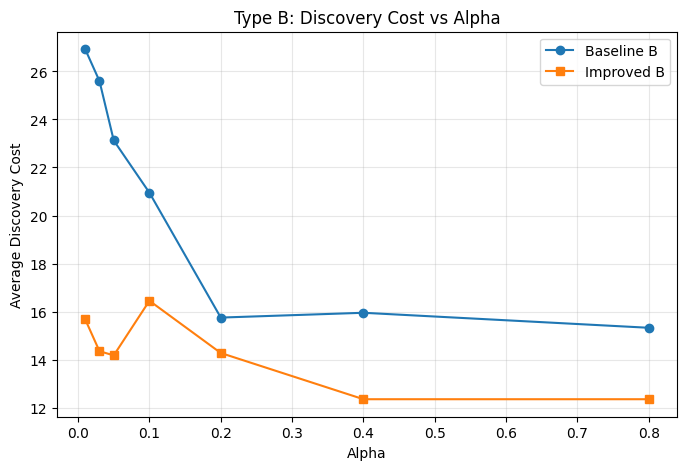

In [132]:
plt.figure(figsize=(8, 5))

plt.plot(summary_b.index, summary_b["baseline_cost"],
         marker="o", label="Baseline B")

plt.plot(summary_b.index, summary_b["improved_cost"],
         marker="s", label="Improved B")

plt.xlabel("Alpha")
plt.ylabel("Average Discovery Cost")
plt.title("Type B: Discovery Cost vs Alpha")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [133]:
alpha_values_large = [
    0.005, 0.01, 0.02, 0.03,
    0.05, 0.08, 0.1, 0.15, 0.2
]

In [135]:
import time

alpha = 0.05
#30*30 TypeB single time run
random.seed(440)
start_time = time.perf_counter()

baseline_large_b = baseline_type_b(
    large_ship, large_start, large_lost, alpha
)

baseline_time = time.perf_counter() - start_time

random.seed(440)
start_time = time.perf_counter()

improved_large_b = improved_type_b(
    large_ship, large_start, large_lost, alpha
)

improved_time = time.perf_counter() - start_time

display(pd.DataFrame([
    {
        "Strategy": "Baseline B",
        "Cost": baseline_large_b["total_cost"],
        "Runtime": baseline_time
    },
    {
        "Strategy": "Improved B",
        "Cost": improved_large_b["total_cost"],
        "Runtime": improved_time
    }
]).round(2))

,Strategy,Cost,Runtime
0,Baseline B,100.5,0.03
1,Improved B,116.0,0.05


In [136]:
#official exp

alpha_values_large = [
    0.005, 0.01, 0.02, 0.03, 0.05,
    0.08, 0.1, 0.15, 0.2
]

num_trials_b_large = 100

random.seed(440)

test_cases_b_large = [
    tuple(random.sample(large_open_cells, 2))
    for _ in range(num_trials_b_large)
]

results_b_large = []

for alpha in alpha_values_large:

    for trial, (start, lost_pos) in enumerate(test_cases_b_large):

        random.seed(440 + trial)
        baseline = baseline_type_b(
            large_ship, start, lost_pos, alpha
        )

        random.seed(440 + trial)
        improved = improved_type_b(
            large_ship, start, lost_pos, alpha
        )

        results_b_large.append({
            "alpha": alpha,
            "trial": trial,
            "baseline_cost": baseline["total_cost"],
            "improved_cost": improved["total_cost"],
            "baseline_moves": baseline["moves"],
            "improved_moves": improved["moves"],
            "baseline_detections": baseline["detections"],
            "improved_detections": improved["detections"]
        })

    print("Finished alpha =", alpha)


Finished alpha = 0.005
Finished alpha = 0.01
Finished alpha = 0.02
Finished alpha = 0.03
Finished alpha = 0.05
Finished alpha = 0.08
Finished alpha = 0.1
Finished alpha = 0.15
Finished alpha = 0.2


In [137]:
df_b_large = pd.DataFrame(results_b_large)

summary_b_large = df_b_large.groupby("alpha")[
    ["baseline_cost", "improved_cost"]
].mean()

summary_b_large["improvement_%"] = (
    (summary_b_large["baseline_cost"] -
     summary_b_large["improved_cost"])
    / summary_b_large["baseline_cost"] * 100
)

display(summary_b_large.round(2))

,baseline_cost,improved_cost,improvement_%
alpha,,,
0.005,666.09,279.02,58.11
0.010,484.66,213.28,55.99
0.020,391.56,189.90,51.50
0.030,358.71,192.44,46.35
0.050,342.85,169.32,50.62
0.080,325.28,156.91,51.76
0.100,330.52,159.10,51.87
0.150,349.50,144.51,58.65
0.200,431.95,145.60,66.29


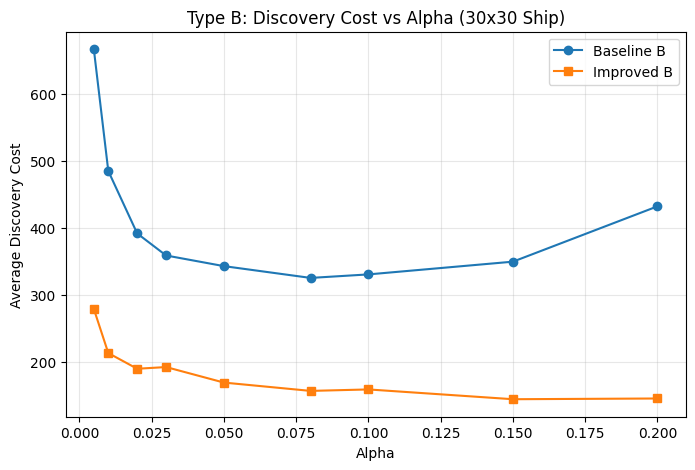

In [138]:
plt.figure(figsize=(8, 5))

plt.plot(
    summary_b_large.index,
    summary_b_large["baseline_cost"],
    marker="o",
    label="Baseline B"
)

plt.plot(
    summary_b_large.index,
    summary_b_large["improved_cost"],
    marker="s",
    label="Improved B"
)

plt.xlabel("Alpha")
plt.ylabel("Average Discovery Cost")
plt.title("Type B: Discovery Cost vs Alpha (30x30 Ship)")

plt.grid(alpha=0.3)
plt.legend()
plt.show()